# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [28]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [29]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [31]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [32]:
numbers = list(range(10))  # список для shuffle

# TODO: двічі ДО set_seed() -- наприклад random.randint(1, 100) і random.shuffle(numbers)
print(random.randint(1, 100))
random.shuffle(numbers)
print(numbers)

numbers = list(range(10))

print(random.randint(1, 100))
random.shuffle(numbers)
print(numbers)

set_seed()
print("Seed зафіксовано:", SEED)

# TODO: тепер двічі ПІСЛЯ set_seed() -- виклич set_seed() перед КОЖНИМ окремим генеруванням
print(random.randint(1, 100))
numbers = list(range(10))
random.shuffle(numbers)
print(numbers)

set_seed()
print(random.randint(1, 100))
numbers = list(range(10))
random.shuffle(numbers)
print(numbers)

# TODO: тепер ще двічі без проміжних викликів set_seed()

set_seed()

print(random.randint(1, 100))
numbers = list(range(10))
random.shuffle(numbers)
print(numbers)

print(random.randint(1, 100))
numbers = list(range(10))
random.shuffle(numbers)
print(numbers)


92
[5, 1, 9, 0, 2, 4, 7, 3, 6, 8]
44
[5, 7, 1, 9, 0, 8, 6, 3, 2, 4]
Seed зафіксовано: 42
82
[7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
82
[7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
82
[7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
76
[4, 3, 2, 9, 5, 1, 7, 8, 0, 6]


seed є стартовою точкою для генерації випадкових чисел, тому коли ми виконуємо reset перед генерацією результат буде таким же як і в минулому. функція set_seed встановлює seed для вбудованої функції, numpy та pytorch

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [33]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cuda
Використовуємо     : cpu
GPU: Tesla T4


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [34]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [35]:
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)


print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)


[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [36]:
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)


print(arange_arr)
print(linspace_arr)


[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [37]:
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity.ndim)
print(random_ints.ndim)


2
2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [38]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

# TODO: порахувати mean, std і z_scores = (scores - mean) / std
mean = np.mean(scores)
std = np.std(scores)
z_scores = z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [39]:
arr = np.arange(1, 13)

# TODO: перетворити arr на матрицю 3x4 (reshape), порахувати суми по рядках
# (axis=1) і по стовпцях (axis=0)
matrix = arr.reshape((3,4))
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [40]:
df = pd.DataFrame({
    "name":  ["Alice", "Bob", "Carol", "Dave", "Eve",
              "Frank", "Grace", "Heidi", "Ivan", "Judy"],
    "score": [78, 85, 92, 67, 90, 74, 88, 95, 60, 82],
}) # додай тут дані для DataFrame

# TODO: відфільтрувати score > 80 і відсортувати за score за спаданням
top = df[df["score"] > 80].sort_values("score", ascending=False)
print(top)


    name  score
7  Heidi     95
2  Carol     92
4    Eve     90
6  Grace     88
1    Bob     85
9   Judy     82


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [41]:
# TODO: додати колонку "grade"
# умови: score >= 90 -> "A", score >= 75 -> "B", інакше -> "C"
df["grade"] = np.where(df["score"] >= 90, "A",
              np.where(df["score"] >= 75, "B", "C"))
print(df)


    name  score grade
0  Alice     78     B
1    Bob     85     B
2  Carol     92     A
3   Dave     67     C
4    Eve     90     A
5  Frank     74     C
6  Grace     88     B
7  Heidi     95     A
8   Ivan     60     C
9   Judy     82     B


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [42]:
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print(zeros_t)
print(zeros_t.shape)
print(zeros_t.dtype)

print(sevens_t)
print(sevens_t.shape)
print(sevens_t.dtype)


tensor([[0., 0., 0.],
        [0., 0., 0.]])
torch.Size([2, 3])
torch.float32
tensor([[7, 7, 7],
        [7, 7, 7]])
torch.Size([2, 3])
torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [43]:
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)


print(arange_t)
print(linspace_t)


tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [44]:
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print(from_list)
print(from_list.shape)
print(from_list.dtype)
print(from_list.ndim)

print(random_t)
print(from_list.shape)
print(from_list.dtype)
print(from_list.ndim)

tensor([[1, 2],
        [3, 4]])
torch.Size([2, 2])
torch.int64
2
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])
torch.Size([2, 2])
torch.int64
2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [45]:
n = 5.0

x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()


print("x.grad        =", x.grad.item())
print("analytic 2*x  =", 2 * n)
print("match:", x.grad.item() == 2 * n)


x.grad        = 10.0
analytic 2*x  = 10.0
match: True


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [60]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for step in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()

    with torch.no_grad():
        x -= lr * x.grad

    x.grad.zero_()

    if step % 5 == 0 or step == 19:
        print(f"step {step:2d}  x = {x.item():.4f}  loss = {loss.item():.4f}")

print(f"\nx = {x.item():.4f}  (minimum at x=3)")

step  0  x = 0.6000  loss = 14.0000
step  5  x = 2.2136  loss = 5.9664
step 10  x = 2.7423  loss = 5.1038
step 15  x = 2.9156  loss = 5.0111
step 19  x = 2.9654  loss = 5.0019

x = 2.9654  (minimum at x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

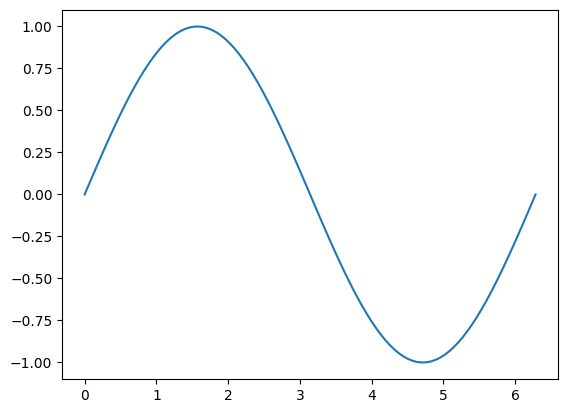

In [47]:
xs = np.linspace(0, 2*np.pi, 100)
plt.plot(xs, np.sin(xs))
plt.show()


**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

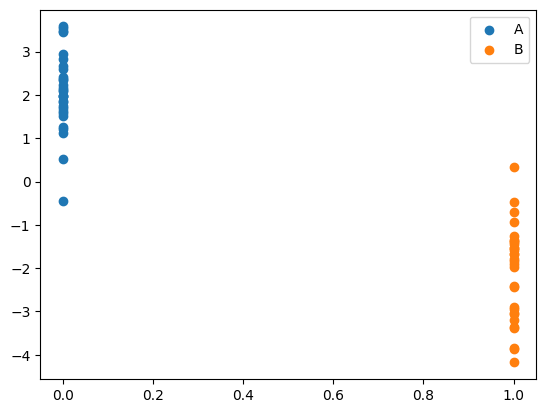

In [48]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

plt.scatter(np.zeros(30), group_a, color="C0", label="A")
plt.scatter(np.ones(30),  group_b, color="C1", label="B")
plt.legend()
plt.show()


---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [49]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

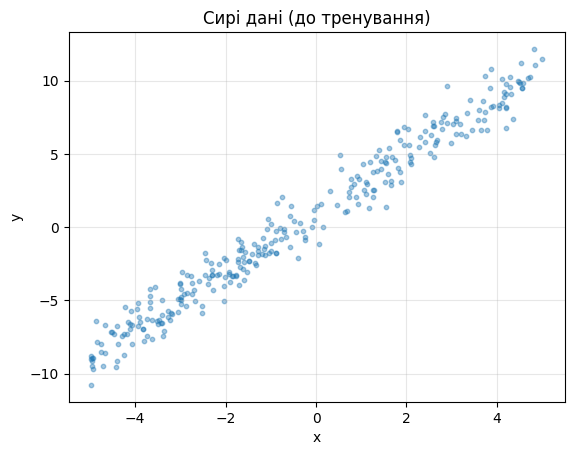

In [50]:
plt.scatter(x1.numpy(), y1.numpy(), s=10, alpha=0.4)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Сирі дані (до тренування)")
plt.grid(alpha=0.3)
plt.show()

**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [51]:
n_train = int(0.70 * TASK1_N)
n_val   = int(0.15 * TASK1_N)

perm = torch.randperm(TASK1_N)

idx_train = perm[:n_train]
idx_val   = perm[n_train:n_train + n_val]
idx_test  = perm[n_train + n_val:]

x_train1, y_train1 = x1[idx_train], y1[idx_train]
x_val1,   y_val1   = x1[idx_val],   y1[idx_val]
x_test1,  y_test1  = x1[idx_test],  y1[idx_test]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")

train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [52]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


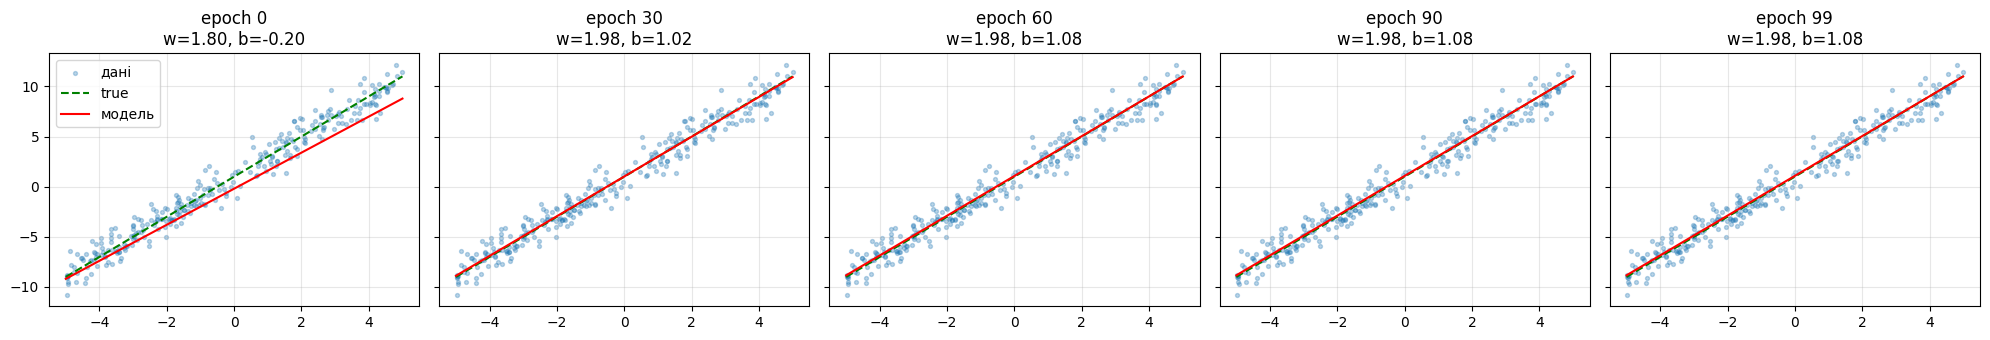

In [53]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

**Сценарій:** залежність між годинами роботи реклами на тиждень
і кількістю нових клієнтів.

**Формула:** clients = 4 * hours + 10 + шум

**Обґрунтування:**
- `w = 4` - одна година реклами приносить приблизно 4 нових клієнти.
  Оцінка: ~2000 показів за годину × 1% CTR × 20% конверсія ≈ 4 клієнти.
- `b = 10` - навіть без реклами є органічний потік клієнтів
  (сарафанне радіо, постійні клієнти) ≈ 10 на тиждень.
- Шум σ = 5 - реальні тижні з однаковою рекламою дають різні результати
  через погоду, свята, активність конкурентів.
- Діапазон x ∈ [0, 20] - від "не рекламуюсь" до "агресивна кампанія".

In [54]:
CSV_PATH   = os.path.join(ARTIFACT_DIR, "dataset.csv")
MODEL_PATH = os.path.join(ARTIFACT_DIR, "model.pt")

TRUE_W    = 4.0
TRUE_B    = 10.0
X_MIN     = 0.0
X_MAX     = 20.0
NOISE_STD = 5.0
N_SAMPLES = 300

In [55]:
# генерація
def generate_data(n=N_SAMPLES, w=TRUE_W, b=TRUE_B,
                  x_min=X_MIN, x_max=X_MAX,
                  noise_std=NOISE_STD, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    x = torch.empty(n, 1).uniform_(x_min, x_max, generator=g)
    noise = noise_std * torch.randn(n, 1, generator=g)
    y = w * x + b + noise
    return x, y


# збереження CSV
def save_to_csv(x, y, path):
    df = pd.DataFrame({
        "ad_hours":    x.squeeze().numpy(),
        "new_clients": y.squeeze().numpy(),
    })
    df.to_csv(path, index=False)
    print(f"Збережено {len(df)} рядків у {path}")


# спліт 70/15/15
def split_data(x, y, ratios=(0.70, 0.15, 0.15), seed=SEED):
    n = len(x)
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(n, generator=g)
    n_train = int(ratios[0] * n)
    n_val   = int(ratios[1] * n)
    idx_train = perm[:n_train]
    idx_val   = perm[n_train:n_train + n_val]
    idx_test  = perm[n_train + n_val:]
    return ((x[idx_train], y[idx_train]),
            (x[idx_val],   y[idx_val]),
            (x[idx_test],  y[idx_test]))


# тренування
def train_linear_regression(x_train, y_train, x_val, y_val,
                            lr=0.005, epochs=300, seed=SEED):
    torch.manual_seed(seed)
    model = torch.nn.Linear(1, 1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()

    history = {"train": [], "val": []}
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        loss = loss_fn(model(x_train), y_train)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(x_val), y_val)
        history["train"].append(loss.item())
        history["val"].append(val_loss.item())

    return model, history


# оцінка
def evaluate(model, x_test, y_test):
    model.eval()
    with torch.no_grad():
        pred = model(x_test)
        mse = torch.nn.functional.mse_loss(pred, y_test).item()
        mae = torch.nn.functional.l1_loss(pred, y_test).item()
    return {"mse": mse, "mae": mae}

In [56]:
# дані
x2, y2 = generate_data()
save_to_csv(x2, y2, CSV_PATH)

# спліт
(x_train2, y_train2), (x_val2, y_val2), (x_test2, y_test2) = split_data(x2, y2)
print(f"train/val/test: {len(x_train2)}/{len(x_val2)}/{len(x_test2)}")

# тренування
task2_model, history2 = train_linear_regression(
    x_train2, y_train2, x_val2, y_val2, lr=0.005, epochs=300
)

# оцінка
metrics2 = evaluate(task2_model, x_test2, y_test2)
print(f"\nЗнайдено:  w={task2_model.weight.item():.3f} (true {TRUE_W}), "
      f"b={task2_model.bias.item():.3f} (true {TRUE_B})")
print(f"Test MSE={metrics2['mse']:.3f}, MAE={metrics2['mae']:.3f}")

Збережено 300 рядків у /content/drive/MyDrive/ai_systems/lab1/dataset.csv
train/val/test: 210/45/45

Знайдено:  w=4.341 (true 4.0), b=6.661 (true 10.0)
Test MSE=28.229, MAE=4.066


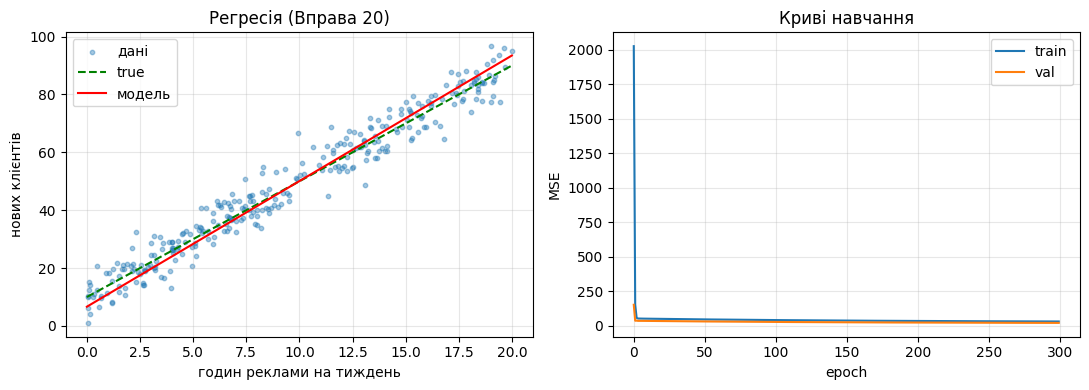

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(x2.numpy(), y2.numpy(), s=10, alpha=0.4, label="дані")
xs2 = torch.linspace(X_MIN, X_MAX, 100).unsqueeze(1)
with torch.no_grad():
    axes[0].plot(xs2.numpy(), (TRUE_W * xs2 + TRUE_B).numpy(),
                 "g--", label="true")
    axes[0].plot(xs2.numpy(), task2_model(xs2).numpy(),
                 "r-", label="модель")
axes[0].set_xlabel("годин реклами на тиждень")
axes[0].set_ylabel("нових клієнтів")
axes[0].set_title("Регресія (Вправа 20)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history2["train"], label="train")
axes[1].plot(history2["val"],   label="val")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("MSE")
axes[1].set_title("Криві навчання")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [58]:
torch.save(task2_model.state_dict(), MODEL_PATH)
print(f"Модель збережено: {MODEL_PATH}")

Модель збережено: /content/drive/MyDrive/ai_systems/lab1/model.pt


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [59]:
!pip install -q gradio
import gradio as gr

loaded_model = torch.nn.Linear(1, 1)
loaded_model.load_state_dict(torch.load(MODEL_PATH))
loaded_model.eval()


def predict_clients(ad_hours):
    x = torch.tensor([[float(ad_hours)]])
    with torch.no_grad():
        y = loaded_model(x).item()
    return round(y, 1)


demo = gr.Interface(
    fn=predict_clients,
    inputs=gr.Slider(X_MIN, X_MAX, value=10, step=0.5,
                     label="Годин реклами на тиждень"),
    outputs=gr.Number(label="Прогноз нових клієнтів"),
    title="Прогноз нових клієнтів за годинами реклами",
    description="Лінійна регресія: clients ≈ 4 × hours + 10",
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://209b55bc9937446fe7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```